In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import plotly.express as px
import plotly.graph_objects as go 
import plotly.io as pio 
import plotly.colors as colors 
import seaborn as sns 
from sklearn.linear_model import LinearRegression


In [2]:
data=pd.read_csv("C:\\Users\\Muskan Kumari\\Downloads\\archive\\housing.csv")
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
data.dropna(inplace=True)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [6]:
from sklearn.model_selection import train_test_split
x=data.drop(['median_house_value'], axis=1)
y=data['median_house_value']

In [7]:
x

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY
...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,INLAND


In [8]:
y

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20433, dtype: float64

In [9]:
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2)

In [10]:
train_data=x_train.join(y_train)

In [11]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
2306,-119.77,36.83,16.0,2360.0,355.0,1034.0,359.0,5.0635,INLAND,108500.0
2986,-119.00,35.33,35.0,991.0,221.0,620.0,207.0,1.9417,INLAND,53800.0
4971,-118.28,34.01,48.0,483.0,190.0,775.0,188.0,2.3309,<1H OCEAN,126600.0
14709,-117.07,32.79,25.0,2489.0,314.0,911.0,309.0,7.8336,NEAR OCEAN,277600.0
5368,-118.40,34.05,43.0,1028.0,145.0,394.0,149.0,10.4519,<1H OCEAN,500001.0
...,...,...,...,...,...,...,...,...,...,...
12388,-116.44,33.77,18.0,4872.0,1110.0,955.0,656.0,2.2439,INLAND,97500.0
16599,-120.70,35.76,15.0,1914.0,425.0,1130.0,421.0,2.2165,<1H OCEAN,90600.0
11898,-117.35,33.96,25.0,2396.0,316.0,951.0,314.0,8.2405,INLAND,235200.0
4171,-118.22,34.10,35.0,4003.0,788.0,2785.0,764.0,4.1213,<1H OCEAN,252100.0


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

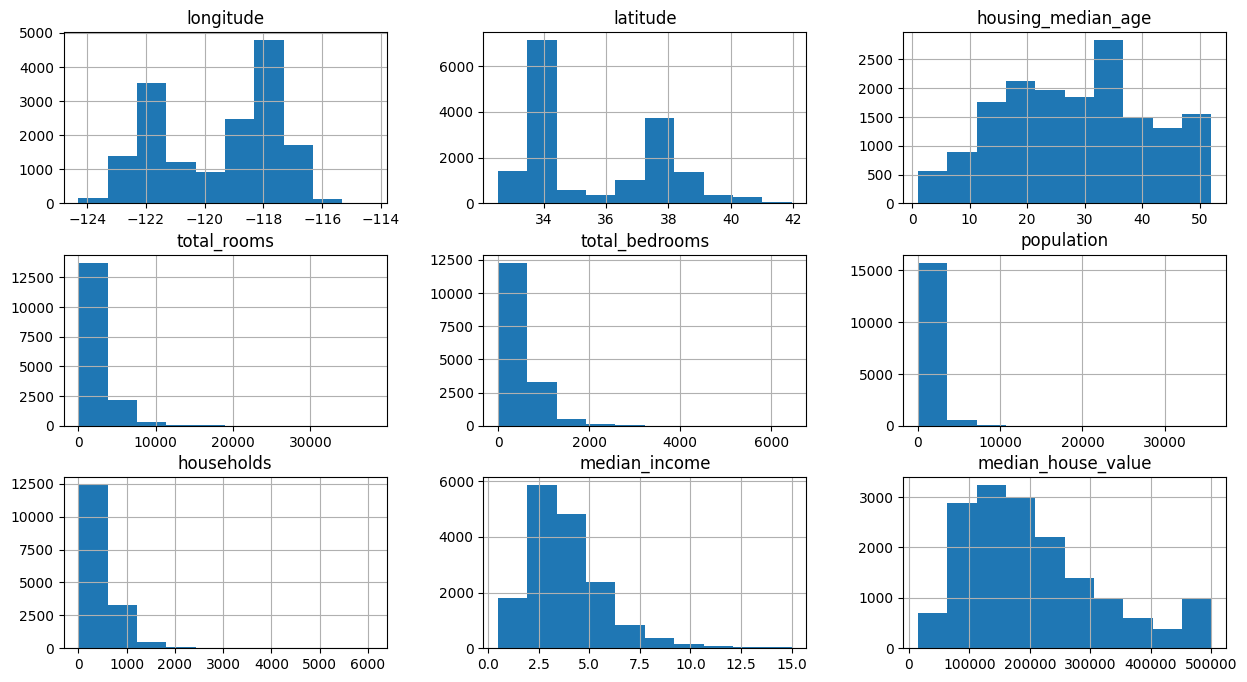

In [12]:
train_data.hist(figsize=(15,8))

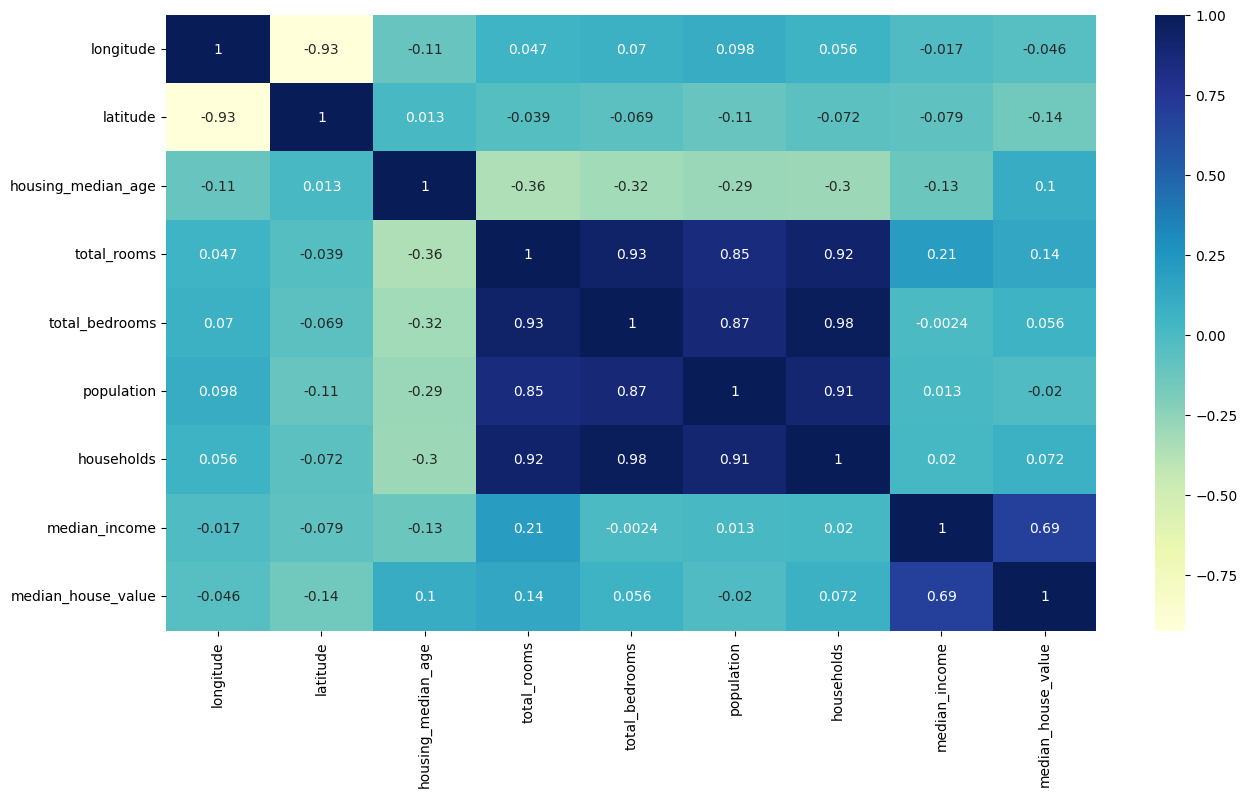

In [13]:
# plt.figure(figsize=(15,8))
# sns.heatmap(train_data.corr(), annot=True, cmap='YlGnBu')
# plt.show()

plt.figure(figsize=(15, 8))

sns.heatmap(
    train_data.select_dtypes(include='number').corr(),
    annot=True,
    cmap='YlGnBu'
)

plt.show()

In [14]:
train_data['total_rooms']=np.log(train_data['total_rooms']+1)
train_data['total_bedrooms']=np.log(train_data['total_bedrooms']+1)
train_data['population']=np.log(train_data['population']+1)
train_data['households']=np.log(train_data['households']+1)


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

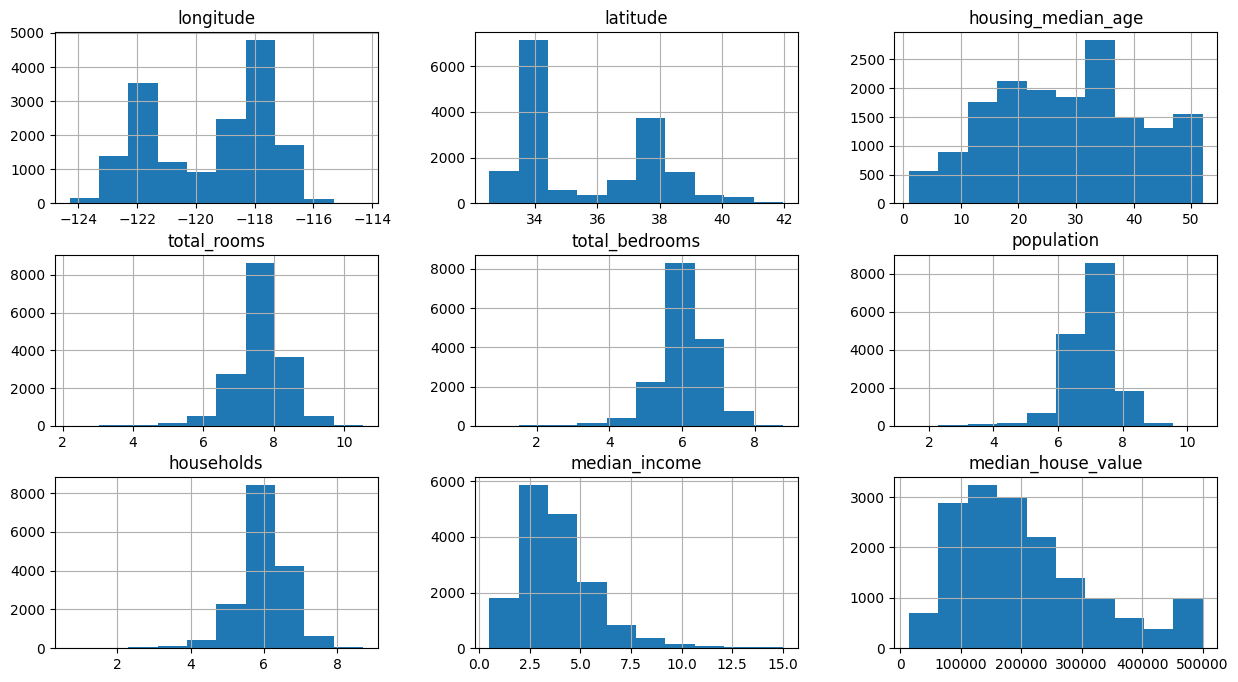

In [15]:
train_data.hist(figsize=(15,8))

In [16]:
train_data=train_data.join(pd.get_dummies(train_data.ocean_proximity,dtype=int)).drop(['ocean_proximity'],axis=1)

In [17]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
2306,-119.77,36.83,16.0,7.766841,5.874931,6.942157,5.886104,5.0635,108500.0,0,1,0,0,0
2986,-119.00,35.33,35.0,6.899723,5.402677,6.431331,5.337538,1.9417,53800.0,0,1,0,0,0
4971,-118.28,34.01,48.0,6.182085,5.252273,6.654153,5.241747,2.3309,126600.0,1,0,0,0,0
14709,-117.07,32.79,25.0,7.820038,5.752573,6.815640,5.736572,7.8336,277600.0,0,0,0,0,1
5368,-118.40,34.05,43.0,6.936343,4.983607,5.978886,5.010635,10.4519,500001.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12388,-116.44,33.77,18.0,8.491465,7.013016,6.862758,6.487684,2.2439,97500.0,0,1,0,0,0
16599,-120.70,35.76,15.0,7.557473,6.054439,7.030857,6.045005,2.2165,90600.0,1,0,0,0,0
11898,-117.35,33.96,25.0,7.781973,5.758902,6.858565,5.752573,8.2405,235200.0,0,1,0,0,0
4171,-118.22,34.10,35.0,8.295049,6.670766,7.932362,6.639876,4.1213,252100.0,1,0,0,0,0


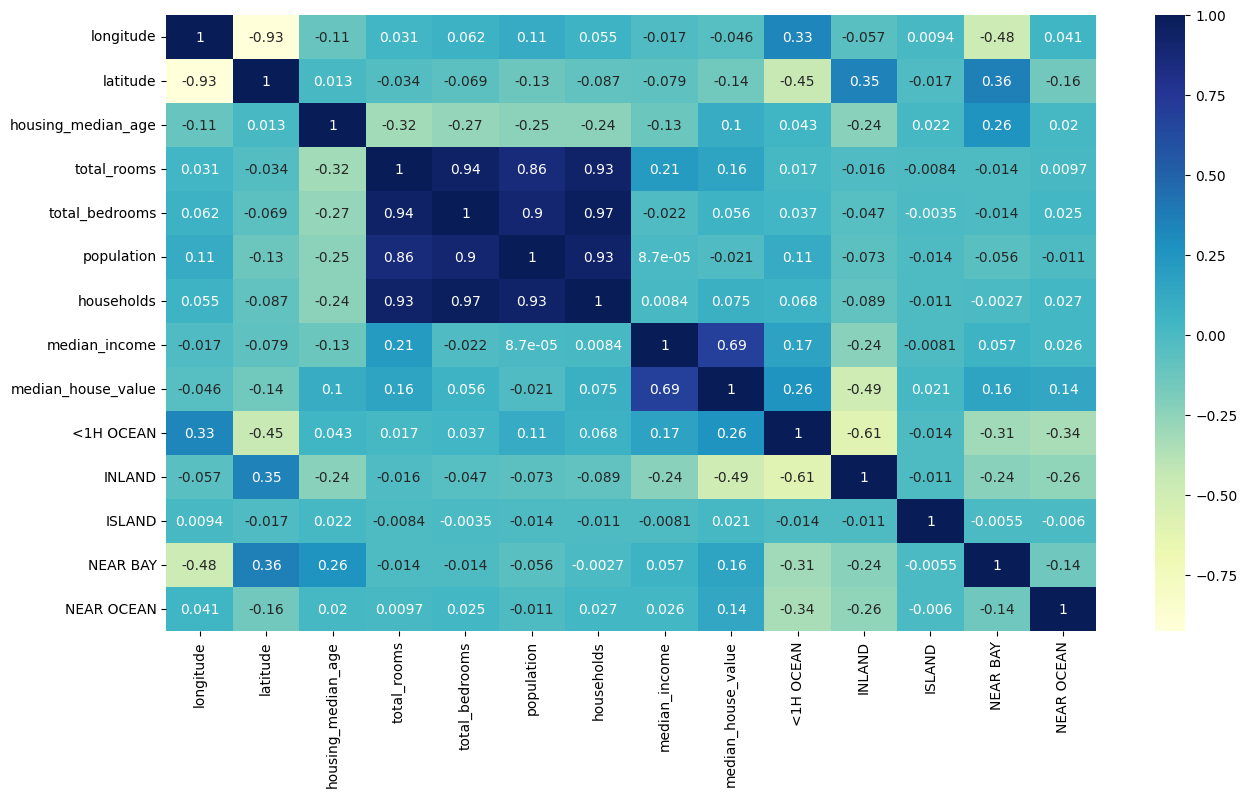

In [18]:
plt.figure(figsize=(15, 8))

sns.heatmap(
    train_data.select_dtypes(include='number').corr(),
    annot=True,
    cmap='YlGnBu'
)

plt.show()

<Axes: xlabel='latitude', ylabel='longitude'>

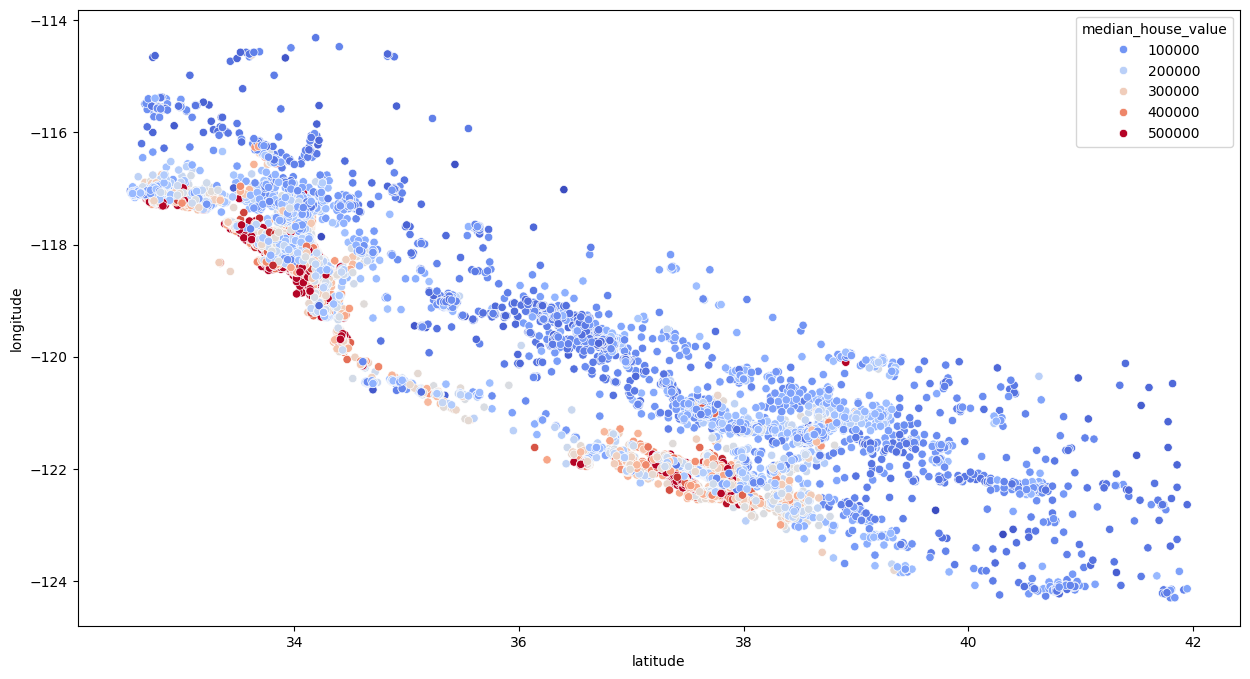

In [19]:
plt.figure(figsize=(15,8))
sns.scatterplot(x="latitude",y="longitude",data=train_data, hue="median_house_value",palette="coolwarm")

In [20]:
train_data['bedroom_ratio']=train_data['total_bedrooms']/train_data['total_rooms']
train_data['household_rooms']=train_data['total_rooms']/train_data['households']

<Axes: >

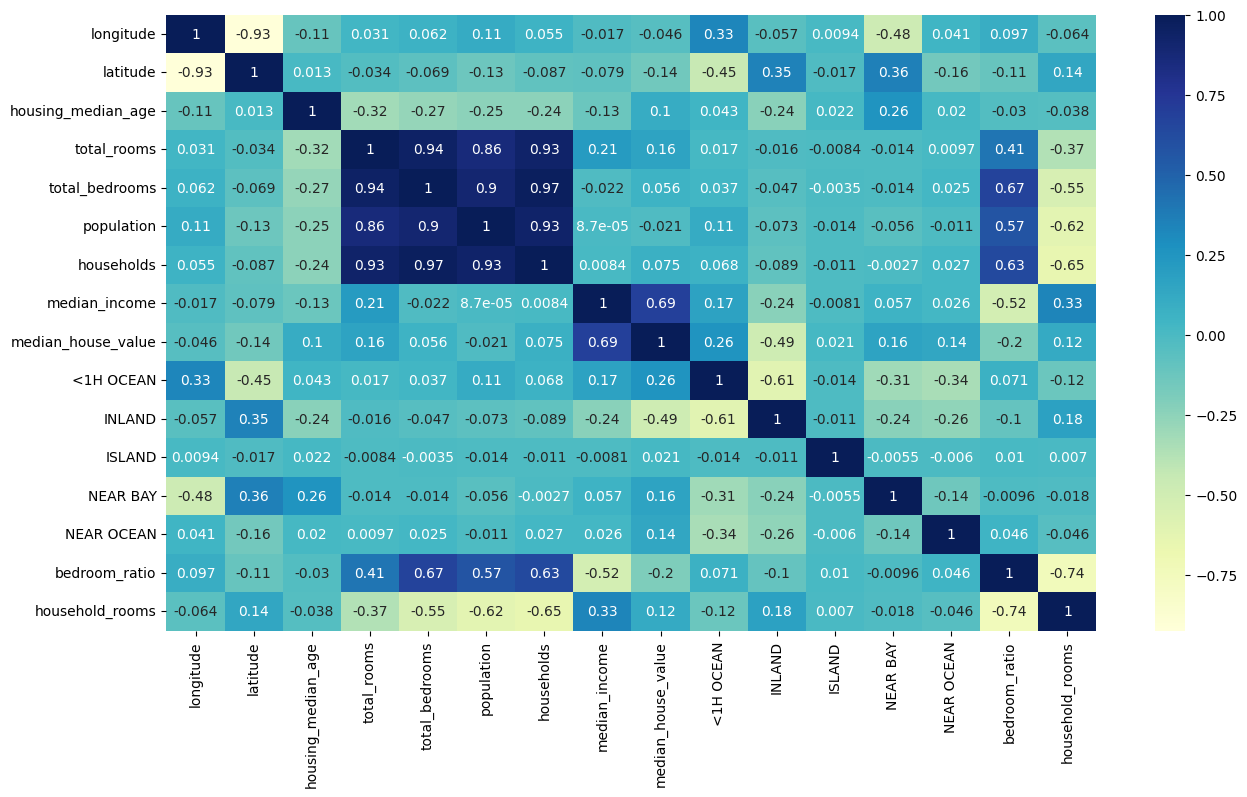

In [21]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(),annot=True,cmap="YlGnBu")

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_train, y_train=train_data.drop(['median_house_value'],axis=1),train_data['median_house_value']
x_train_s=scaler.fit_transform(x_train)
reg=LinearRegression()

reg.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ -29518.77, -28574.86, 1071.18,..., -13189.52,-463895.08, -16211.09]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['longitude','latitude','housing_median_age',...,'NEAR OCEAN', 'bedroom_ratio','household_rooms']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.968e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


In [23]:
test_data=x_test.join(y_test)

test_data['total_rooms']=np.log(test_data['total_rooms']+1)
test_data['total_bedrooms']=np.log(test_data['total_bedrooms']+1)
test_data['population']=np.log(test_data['population']+1)
test_data['households']=np.log(test_data['households']+1)

test_data=test_data.join(pd.get_dummies(test_data.ocean_proximity,dtype=int)).drop(['ocean_proximity'],axis=1)

test_data['bedroom_ratio']=test_data['total_bedrooms']/test_data['total_rooms']
test_data['household_rooms']=test_data['total_rooms']/test_data['households']

x_test, y_test=test_data.drop(['median_house_value'],axis=1),test_data['median_house_value']

In [24]:
x_test_s=scaler.transform(x_test)

In [25]:
reg.score(x_test,y_test)

0.6699344575508349

In [26]:
from sklearn.ensemble import RandomForestRegressor

forest=RandomForestRegressor()

forest.fit(x_train_s,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [27]:
forest.score(x_test_s,y_test)

0.8168946896745174

In [28]:
print(x_test_s.shape)

(4087, 15)


In [29]:
# from sklearn.model_selection import GridSearchCV
# forest=RandomForestRegressor()
# param_grid={
   
#     "n_estimators":[100,200,300],
#     "min_samples_split":[2,4],
#     "max_depth":[None,4,8]
# }
# grid_search=GridSearchCV(forest,param_grid,cv=5,
#                         scoring="neg_mean_squared_error",
#                         return_train_score=True)
# grid_search.fit(x_train_s,y_train)

In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

forest = RandomForestRegressor(random_state=42, n_jobs=-1)

param_grid = {
    "n_estimators": [50, 100],
    "min_samples_split": [2, 4],
    "max_depth": [8, 12]
}

grid_search = GridSearchCV(
    forest,
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(x_train_s, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best RMSE:", (-grid_search.best_score_) ** 0.5)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 100}
Best RMSE: 53202.919280916045


In [31]:
# best_forest=
grid_search.best_estimator_

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [32]:
# best_forest.score(x_test_s,y_test)

In [33]:
grid_search.best_estimator_.score(x_test_s,y_test)

0.7990926213357038

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the model you trained
y_pred = reg.predict(x_test)  # if your model is named reg

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R² Score:", r2_score(y_test, y_pred))

MAE: 47206.682578681546
RMSE: 65603.07761465774
R² Score: 0.6699344575508349


In [36]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

forest = RandomForestRegressor(random_state=42, n_jobs=-1)

param_grid = {
    "n_estimators": [50, 100],
    "min_samples_split": [2, 4],
    "max_depth": [8, 12]
}

grid_search = GridSearchCV(
    forest,
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(x_train_s, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best RMSE:", (-grid_search.best_score_) ** 0.5)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 100}
Best RMSE: 53202.919280916045


MAE: 47206.682578681546
RMSE: 65603.07761465774
R² Score: 0.6699344575508349


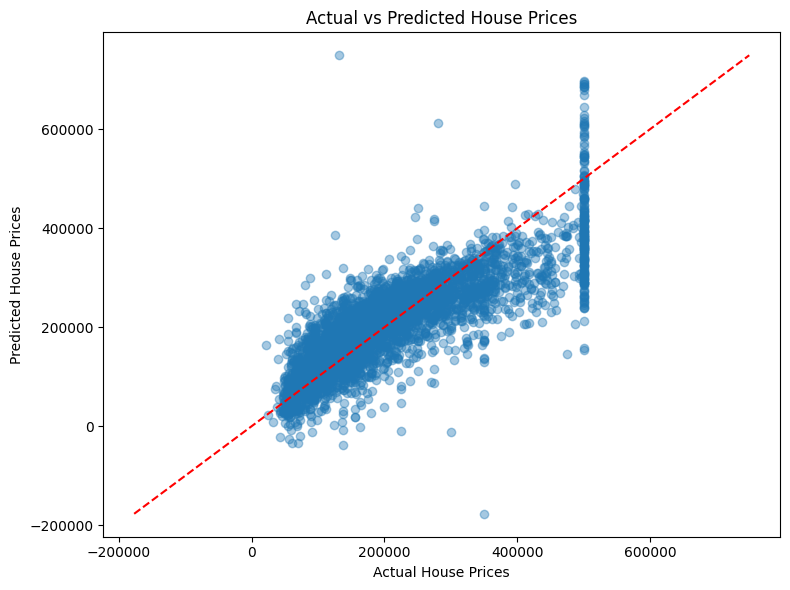

In [37]:

import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Predict house prices
y_pred = reg.predict(x_test)  # Replace reg with your trained model's variable name

# Step 2: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

# Step 3: Plot actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# Ideal prediction line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())
plt.plot([min_price, max_price], [min_price, max_price], "r--")

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()


In [38]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

linear_pred = linear_model.predict(x_test)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, linear_pred))
print("RMSE:", mean_squared_error(y_test, linear_pred) ** 0.5)
print("R² Score:", r2_score(y_test, linear_pred))


Linear Regression
MAE: 47206.682578681546
RMSE: 65603.07761465774
R² Score: 0.6699344575508349


In [39]:

from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=4,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(x_train, y_train)

forest_pred = forest_model.predict(x_test)

print("Random Forest")
print("MAE:", mean_absolute_error(y_test, forest_pred))
print("RMSE:", mean_squared_error(y_test, forest_pred) ** 0.5)
print("R² Score:", r2_score(y_test, forest_pred))


Random Forest
MAE: 32990.66332279371
RMSE: 49551.07274386882
R² Score: 0.8116967209759852


In [40]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [12, 20, None],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(x_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", (-grid_search.best_score_) ** 0.5)

best_model = grid_search.best_estimator_
best_pred = best_model.predict(x_test)

print("Test MAE:", mean_absolute_error(y_test, best_pred))
print("Test RMSE:", mean_squared_error(y_test, best_pred) ** 0.5)
print("Test R²:", r2_score(y_test, best_pred))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV RMSE: 51146.58926189528
Test MAE: 32189.017675556646
Test RMSE: 48738.57621501706
Test R²: 0.817821367919696


In [41]:

best_model = grid_search.best_estimator_

predictions = best_model.predict(x_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Best Parameters:", grid_search.best_params_)
print("Tuned Random Forest")
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", mean_squared_error(y_test, predictions) ** 0.5)
print("R² Score:", r2_score(y_test, predictions))


Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Tuned Random Forest
MAE: 32189.017675556646
RMSE: 48738.57621501706
R² Score: 0.817821367919696


In [42]:


import pandas as pd

# Create a table of actual and predicted prices
results = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": predictions
})

# Save as CSV
results.to_csv("HousePricePred.csv", index=False)

print("File saved as HousePricePred.csv")
print(results.head())



File saved as HousePricePred.csv
   Actual_Price  Predicted_Price
0      350000.0       233422.510
1      500001.0       413382.665
2      154700.0       127900.500
3       88300.0       105621.000
4      225000.0       287741.065


In [43]:
import os
print(os.getcwd())

C:\Users\Muskan Kumari\jupyterrr\projects\2ndProject


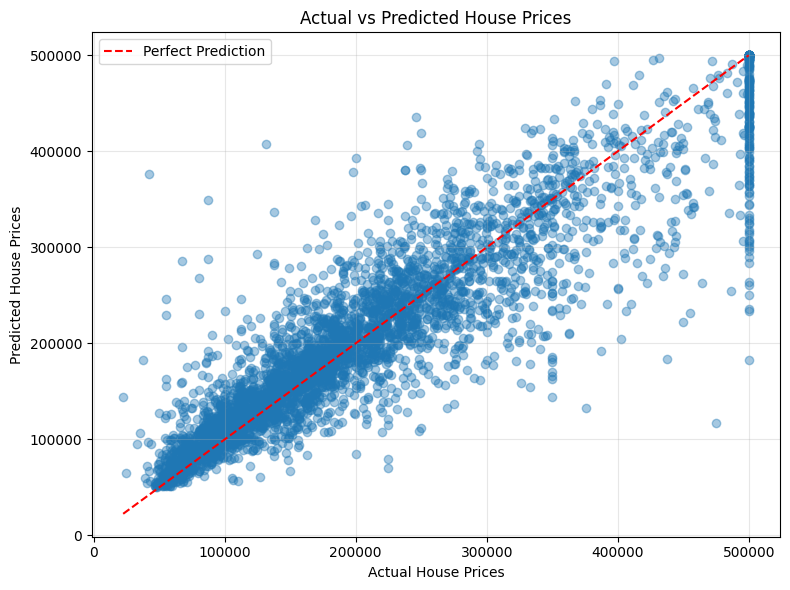

In [44]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

# Ideal prediction line
min_price = min(y_test.min(), predictions.min())
max_price = max(y_test.max(), predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


               Feature  Importance
7        median_income    0.480002
9               INLAND    0.143678
0            longitude    0.096526
1             latitude    0.086401
2   housing_median_age    0.050233
13       bedroom_ratio    0.032694
5           population    0.026524
14     household_rooms    0.024993
3          total_rooms    0.020197
4       total_bedrooms    0.014355
6           households    0.012991
12          NEAR OCEAN    0.006459
8            <1H OCEAN    0.003943
11            NEAR BAY    0.000831
10              ISLAND    0.000175


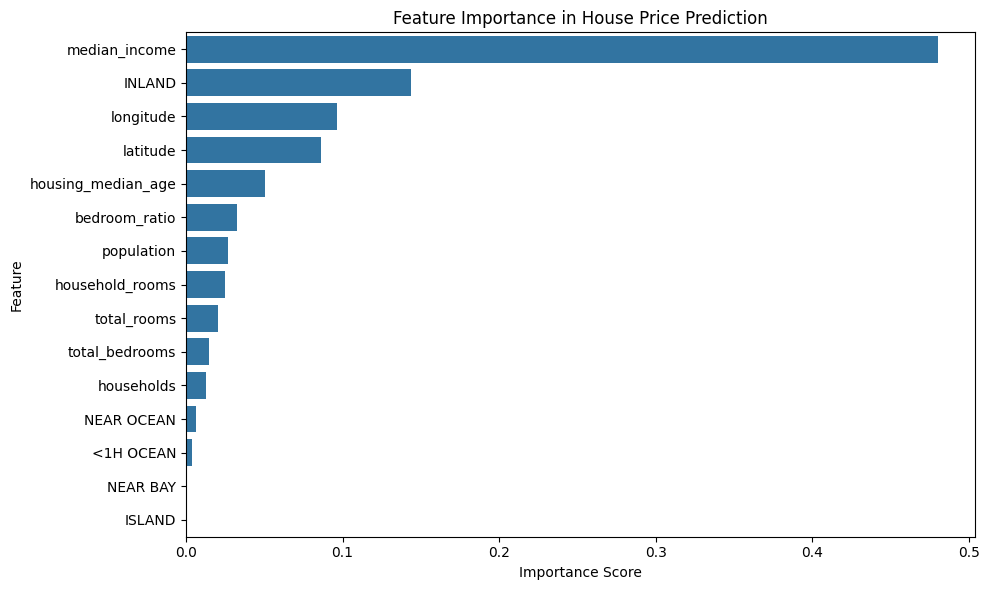

In [45]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from your trained Random Forest model
importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": best_model.feature_importances_
})

# Sort features from most to least important
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in House Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


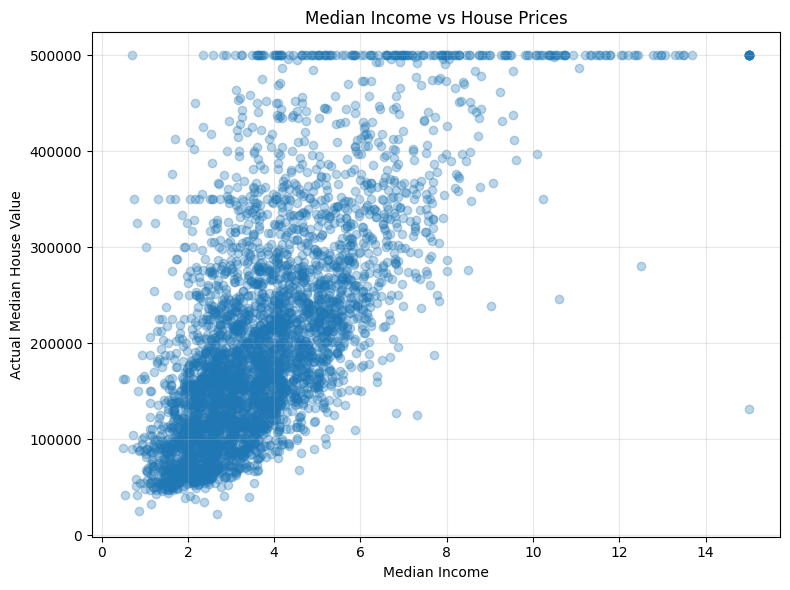

In [46]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    x_test["median_income"],
    y_test,
    alpha=0.3
)

plt.xlabel("Median Income")
plt.ylabel("Actual Median House Value")
plt.title("Median Income vs House Prices")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [47]:
import joblib

joblib.dump(best_model, "HousePricePred.pkl")

print("Model saved successfully!")

Model saved successfully!


In [48]:
import joblib

loaded_model = joblib.load("HousePricePred.pkl")